**Data-driven player roles from Wyscout event data (2017/18)**

Derives outfield roles from event data for the top-5 European leagues and ranks players within the role they actually play, using VAEP action values.

## 1. Install

In [1]:
!pip -q install socceraction==0.2.0 mplsoccer

## 2. Setup: paths and leagues

In [2]:
import warnings
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=pd.io.pytables.PerformanceWarning)

DATA = Path("/kaggle/input/datasets/bouldog503/transfers")
WORK = Path("/kaggle/working")
RAW_H5 = WORK / "wyscout.h5"
SPADL_H5 = WORK / "spadl.h5"

# Club leagues only: this project is about roles within leagues, not tournaments
LEAGUES = {"England": "Premier League", "Spain": "La Liga", "Italy": "Serie A",
           "Germany": "Bundesliga", "France": "Ligue 1"}

## 3. Load Wyscout events and convert to SPADL

In [3]:
from socceraction.spadl.wyscout import convert_to_spadl

teams = pd.read_json(DATA / "teams.json")
players = pd.read_json(DATA / "players.json")

matches, events = [], []
for country, league in LEAGUES.items():
    m = pd.read_json(DATA / "matches" / f"matches_{country}.json")
    m["league"] = league
    matches.append(m)
    events.append(pd.read_json(DATA / "events" / f"events_{country}.json"))
matches = pd.concat(matches, ignore_index=True)
events = pd.concat(events, ignore_index=True)

# dates as strings so the HDF store accepts them
for c in ["date", "dateutc"]:
    matches[c] = matches[c].astype(str)

if RAW_H5.exists():
    RAW_H5.unlink()
teams.to_hdf(RAW_H5, key="teams", mode="w", format="fixed")
players.to_hdf(RAW_H5, key="players", mode="a", format="fixed")
matches.drop(columns="league").to_hdf(RAW_H5, key="matches", mode="a", format="fixed")
with pd.HDFStore(RAW_H5, mode="a") as store:
    for match_id, ev in tqdm(events.groupby("matchId")):
        store.put(f"events/match_{int(match_id)}", ev, format="fixed")

convert_to_spadl(str(RAW_H5), str(SPADL_H5))

print(matches["league"].value_counts())
print("events:", len(events))
with pd.HDFStore(SPADL_H5, "r") as s:
    print("SPADL games:", sum(k.startswith("/actions/game_") for k in s.keys()))

  0%|          | 0/1826 [00:00<?, ?it/s]

...Inserting actiontypes
...Inserting bodyparts
...Inserting results
...Converting games
...Converting players
...Converting teams
...Generating player_games


100%|██████████| 1826/1826 [02:11<00:00, 13.92game/s]


...Converting events to actions


  0%|          | 0/1826 [00:00<?, ?game/s]/usr/local/lib/python3.13/dist-packages/socceraction/spadl/wyscout.py:337: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  lambda x: make_position_vars(x[0], x[1]), axis=1
/usr/local/lib/python3.13/dist-packages/socceraction/spadl/wyscout.py:426: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '55.38' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_events.loc[post_left_idx, "end_y"] = 55.38
  0%|          | 1/1826 [00:00<18:24,  1.65game/s]/usr/local/lib/python3.13/dist-packages/socceraction/spadl/wyscout.py:337: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be trea

league
Premier League    380
La Liga           380
Serie A           380
Ligue 1           380
Bundesliga        306
Name: count, dtype: int64
events: 3071395
SPADL games: 1826


## 4. VAEP features and labels (actions oriented in each team's attacking direction)

In [4]:
import numpy as np
import socceraction.vaep.features as fs
import socceraction.vaep.labels as lab

NB_PREV = 3
FEATURE_FNS = [fs.actiontype_onehot, fs.bodypart_onehot, fs.result_onehot,
               fs.goalscore, fs.startlocation, fs.endlocation, fs.movement,
               fs.space_delta, fs.startpolar, fs.endpolar, fs.team, fs.time_delta]
FEATURE_COLS = fs.feature_column_names(FEATURE_FNS, nb_prev_actions=NB_PREV)

games = pd.read_hdf(SPADL_H5, "games")
actiontypes = pd.read_hdf(SPADL_H5, "actiontypes")
results = pd.read_hdf(SPADL_H5, "results")
bodyparts = pd.read_hdf(SPADL_H5, "bodyparts")

acts, X, Y = [], [], []
for _, g in tqdm(games.iterrows(), total=len(games)):
    a = pd.read_hdf(SPADL_H5, f"actions/game_{int(g.game_id)}")
    a = (a.sort_values(["period_id", "time_seconds"], kind="mergesort")
          .merge(actiontypes, on="type_id", how="left")
          .merge(results, on="result_id", how="left")
          .merge(bodyparts, on="bodypart_id", how="left")
          .reset_index(drop=True))
    states = fs.play_left_to_right(fs.gamestates(a, nb_prev_actions=NB_PREV), g.home_team_id)
    X.append(pd.concat([fn(states) for fn in FEATURE_FNS], axis=1)[FEATURE_COLS].astype("float32"))
    Y.append(pd.concat([lab.scores(a), lab.concedes(a)], axis=1))
    acts.append(a)

actions = pd.concat(acts, ignore_index=True)
X = pd.concat(X, ignore_index=True)
Y = pd.concat(Y, ignore_index=True).astype(int)
assert len(actions) == len(X) == len(Y)
print("actions:", actions.shape, "features:", X.shape)
print(Y.mean().round(4))

  0%|          | 0/1826 [00:00<?, ?it/s]

actions: (2321480, 15) features: (2321480, 142)
scores      0.0156
concedes    0.0050
dtype: float64


## 5. Out-of-fold XGBoost by match and VAEP values

In [5]:
from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, brier_score_loss
try:
    from socceraction.vaep.formula import value
except ImportError:
    from socceraction.vaep.value import value

groups = actions["game_id"].values
P = pd.DataFrame(index=actions.index, columns=["scores", "concedes"], dtype=float)

for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, groups=groups)):
    for target in ["scores", "concedes"]:
        m = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8,
                          tree_method="hist", n_jobs=-1, random_state=42)
        m.fit(X.iloc[tr], Y[target].iloc[tr])
        P.loc[te, target] = m.predict_proba(X.iloc[te])[:, 1]
    print(f"fold {fold + 1}/5 done")

model_metrics = pd.DataFrame({t: {"AUC": roc_auc_score(Y[t], P[t]),
                                  "Brier": brier_score_loss(Y[t], P[t])}
                              for t in ["scores", "concedes"]}).T
print(model_metrics.round(4))

values = value(actions, P["scores"], P["concedes"])
vaep = pd.concat([actions, P, values], axis=1)
vaep.to_parquet(WORK / "vaep_actions.parquet", index=False)
print(vaep[["offensive_value", "defensive_value", "vaep_value"]].describe().round(4))

fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done
             AUC   Brier
scores    0.7780  0.0129
concedes  0.7379  0.0048
       offensive_value  defensive_value    vaep_value
count     2.321480e+06     2.321480e+06  2.321480e+06
mean      3.200000e-03     1.000000e-04  3.300000e-03
std       4.240000e-02     1.290000e-02  4.440000e-02
min      -7.841000e-01    -7.679000e-01 -7.917000e-01
25%      -1.700000e-03    -1.100000e-03 -2.800000e-03
50%       8.000000e-04    -0.000000e+00  1.100000e-03
75%       4.400000e-03     8.000000e-04  5.700000e-03
max       9.939000e-01     6.817000e-01  9.991000e-01


## 6. Player profiles (≥ 900 minutes): location, action mix, VAEP per 90

In [6]:
import re

def fix_name(s):
    """Wyscout stores names with literal \\uXXXX escapes."""
    return re.sub(r"\\u([0-9a-fA-F]{4})", lambda m: chr(int(m.group(1), 16)), s) if isinstance(s, str) else s

MIN_MINUTES = 900
league_of_game = matches.set_index("wyId")["league"]

# 1. Every action from the acting team's attacking direction (left to right).
#    The VAEP features already hold these coordinates (play_left_to_right), row-aligned with the actions.
v = vaep.copy()
for c in ["start_x", "start_y", "end_x", "end_y"]:
    v[c] = X[f"{c}_a0"].values

# 2. Action-profile flags
t = v["type_name"]
v["is_pass"] = t.isin(["pass", "freekick_short", "corner_short", "throw_in"])
v["is_cross"] = t.isin(["cross", "freekick_crossed", "corner_crossed"])
v["is_dribble"] = t.isin(["dribble", "take_on"])
v["is_shot"] = t.isin(["shot", "shot_freekick", "shot_penalty"])
v["is_defensive"] = t.isin(["tackle", "interception", "clearance"])
v["is_progressive"] = v["is_pass"] & ((v["end_x"] - v["start_x"]) >= 10)
v["in_final_third"] = v["start_x"] >= 70
v["width"] = (v["start_y"] - 34).abs()
v["league"] = v["game_id"].map(league_of_game)

# 3. Player level (whole season, all clubs)
agg = v.groupby("player_id").agg(
    n_actions=("vaep_value", "size"), vaep=("vaep_value", "sum"),
    off=("offensive_value", "sum"), deff=("defensive_value", "sum"),
    mean_x=("start_x", "mean"), mean_width=("width", "mean"),
    pass_share=("is_pass", "mean"), cross_share=("is_cross", "mean"),
    dribble_share=("is_dribble", "mean"), shot_share=("is_shot", "mean"),
    def_share=("is_defensive", "mean"), prog_share=("is_progressive", "mean"),
    final_third_share=("in_final_third", "mean"),
    league=("league", lambda s: s.mode().iat[0]),
    team_id=("team_id", lambda s: s.mode().iat[0]),
).reset_index()

pg = pd.read_hdf(SPADL_H5, "player_games")
mins = pg.groupby("player_id").agg(minutes=("minutes_played", "sum"),
                                   games=("game_id", "nunique")).reset_index()

info = players.assign(
    name=players["shortName"].map(fix_name),
    official_role=players["role"].map(lambda d: d.get("code2") if isinstance(d, dict) else None),
)[["wyId", "name", "official_role", "birthDate"]].rename(columns={"wyId": "player_id"})
team_names = teams.assign(team=teams["name"].map(fix_name))[["wyId", "team"]].rename(columns={"wyId": "team_id"})

df = (agg.merge(mins, on="player_id").merge(info, on="player_id", how="left")
         .merge(team_names, on="team_id", how="left"))
df["official_role"] = df["official_role"].replace({"MD": "MF"})
for c in ["vaep", "off", "deff"]:
    df[f"{c}_p90"] = df[c] * 90 / df["minutes"]

df = df[df["minutes"] >= MIN_MINUTES].reset_index(drop=True)
df.to_csv(WORK / "players_2017_18.csv", index=False)

print(df.shape)
print(df["official_role"].value_counts())
print(df.groupby("official_role")[["mean_x", "mean_width", "pass_share", "cross_share",
                                    "shot_share", "def_share"]].mean().round(3))
df.sort_values("vaep_p90", ascending=False)[["name", "team", "official_role", "minutes", "vaep_p90"]].head(10)

(1665, 25)
official_role
DF    612
MF    596
FW    336
GK    121
Name: count, dtype: int64
                  mean_x  mean_width  pass_share  cross_share  shot_share  \
official_role                                                               
DF             43.153999      19.594       0.765        0.026       0.007   
FW             67.635002      17.500       0.605        0.045       0.060   
GK             10.913000       5.172       0.617        0.000       0.000   
MF             56.960999      16.930       0.713        0.045       0.021   

               def_share  
official_role             
DF                 0.116  
FW                 0.057  
GK                 0.049  
MF                 0.076  


,name,team,official_role,minutes,vaep_p90
85,L. Messi,Barcelona,FW,3107.979597,1.096675
1026,Neymar,PSG,FW,1856.207752,1.053154
1206,Mohamed Salah,Liverpool,FW,2996.529579,0.775290
172,Philippe Coutinho,Barcelona,FW,2463.779299,0.682090
967,N. Fekir,Olympique Lyonnais,MF,2576.731738,0.667418
1226,S. Gnabry,Hoffenheim,MF,1534.906306,0.651527
1158,P. Dybala,Juventus,FW,2451.475153,0.644314
158,A. Griezmann,Atlético Madrid,FW,2620.010232,0.643584
326,G. Bale,Real Madrid,FW,1852.140087,0.632391
11,M. Depay,Olympique Lyonnais,FW,2634.701474,0.606547


## 7. How many roles? Silhouette and bootstrap stability

    k  silhouette  stability_ARI  ARI_sd
0   3       0.334          0.953   0.032
1   4       0.347          0.982   0.011
2   5       0.328          0.971   0.014
3   6       0.307          0.885   0.103
4   7       0.279          0.838   0.095
5   8       0.271          0.798   0.090
6   9       0.240          0.786   0.096
7  10       0.241          0.730   0.081


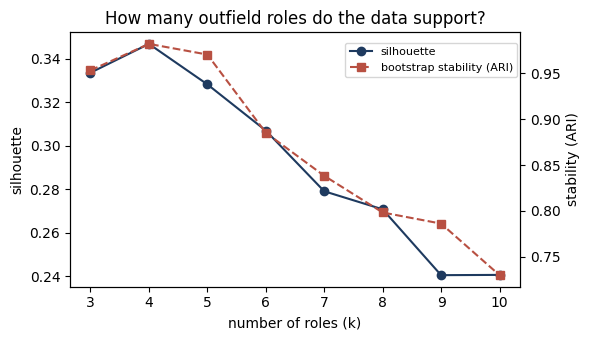

In [7]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

PROFILE = ["mean_x", "mean_width", "pass_share", "cross_share", "dribble_share",
           "shot_share", "def_share", "prog_share", "final_third_share"]

out = df[df["official_role"] != "GK"].reset_index(drop=True)
Z = StandardScaler().fit_transform(out[PROFILE])

rng = np.random.default_rng(42)
rows = []
for k in range(3, 11):
    base = KMeans(n_clusters=k, n_init=50, random_state=42).fit(Z)
    aris = []
    for _ in range(30):
        idx = rng.choice(len(Z), len(Z), replace=True)
        boot = KMeans(n_clusters=k, n_init=10, random_state=int(rng.integers(1e6))).fit(Z[idx])
        aris.append(adjusted_rand_score(base.labels_, boot.predict(Z)))
    rows.append({"k": k, "silhouette": silhouette_score(Z, base.labels_),
                 "stability_ARI": np.mean(aris), "ARI_sd": np.std(aris)})

k_table = pd.DataFrame(rows)
print(k_table.round(3))

fig, ax1 = plt.subplots(figsize=(6, 3.5))
ax1.plot(k_table["k"], k_table["silhouette"], "o-", color="#1E3A5F", label="silhouette")
ax1.set_xlabel("number of roles (k)"); ax1.set_ylabel("silhouette")
ax2 = ax1.twinx()
ax2.plot(k_table["k"], k_table["stability_ARI"], "s--", color="#B85042", label="bootstrap stability (ARI)")
ax2.set_ylabel("stability (ARI)")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88), fontsize=8)
ax1.set_title("How many outfield roles do the data support?")
plt.tight_layout()
plt.savefig(WORK / "fig_choose_k.png", dpi=150)
plt.show()

## 8. Role profiles for k = 4 and k = 5

In [8]:
def fit_roles(k):
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(Z)
    # order clusters from deepest to most advanced, so labels are readable
    order = out.groupby(km.labels_)["mean_x"].mean().sort_values().index
    remap = {old: new for new, old in enumerate(order)}
    return pd.Series(km.labels_, index=out.index).map(remap)

for k in [4, 5]:
    out[f"role_k{k}"] = fit_roles(k)
    print(f"\n================  k = {k}  ================")
    prof = out.groupby(f"role_k{k}")[PROFILE + ["vaep_p90"]].mean()
    prof.insert(0, "n", out[f"role_k{k}"].value_counts().sort_index())
    print(prof.round(3).to_string())
    print("\nvs official Wyscout role:")
    print(pd.crosstab(out[f"role_k{k}"], out["official_role"]))
    print("\nmost-used players per cluster:")
    for c, g in out.groupby(f"role_k{k}"):
        print(f"  {c}: " + ", ".join(g.nlargest(6, "minutes")["name"]))


================  k = 4  ================
           n     mean_x  mean_width  pass_share  cross_share  dribble_share  shot_share  def_share  prog_share  final_third_share  vaep_p90
role_k4                                                                                                                                    
0        362  36.955002   14.817000       0.783        0.005          0.055       0.007      0.133       0.342              0.054     0.144
1        326  52.272999   24.832001       0.737        0.056          0.089       0.009      0.092       0.255              0.279     0.166
2        354  53.764999   14.953000       0.754        0.024          0.098       0.017      0.081       0.232              0.235     0.202
3        502  66.997002   18.344999       0.610        0.059          0.189       0.052      0.056       0.134              0.518     0.225

vs official Wyscout role:
official_role   DF   FW   MF
role_k4                     
0              332    0   30
1  

## 9. Final roles and pitch map

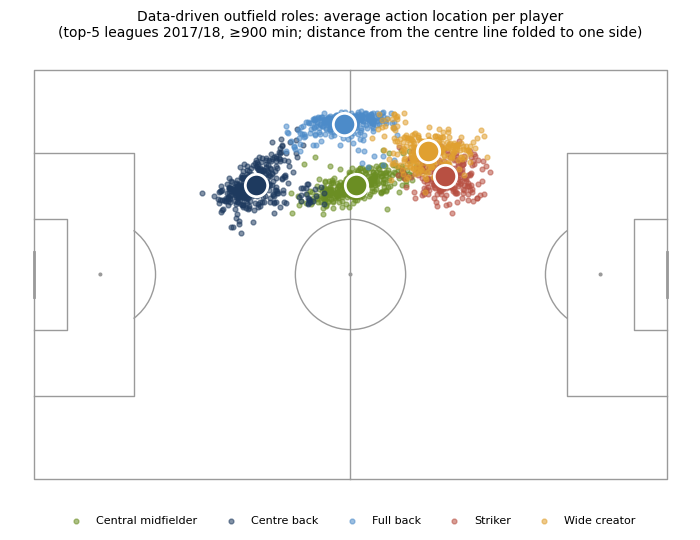

official_role        DF   FW   GK   MF
role                                  
Central midfielder    4    8    0  340
Centre back         328    0    0   26
Full back           273    4    0   25
Goalkeeper            0    0  121    0
Striker               0  235    0   15
Wide creator          7   89    0  190


In [9]:
from mplsoccer import Pitch

ROLE_NAMES = {0: "Centre back", 1: "Full back", 2: "Central midfielder",
              3: "Wide creator", 4: "Striker"}
out["role"] = out["role_k5"].map(ROLE_NAMES)

# Goalkeepers keep their official role; outfield players get the data-driven one
gk = df[df["official_role"] == "GK"].assign(role="Goalkeeper")
roles = pd.concat([out, gk], ignore_index=True)
roles.to_csv(WORK / "player_roles_2017_18.csv", index=False)

# Figure: where each role plays (average action location, one dot per player)
COLORS = {"Centre back": "#1E3A5F", "Full back": "#4C8BC9", "Central midfielder": "#6B8E23",
          "Wide creator": "#E0A030", "Striker": "#B85042"}
pitch = Pitch(pitch_type="custom", pitch_length=105, pitch_width=68,
              line_color="#9a9a9a", linewidth=1)
fig, ax = pitch.draw(figsize=(8, 5.5))
for role, g in out.groupby("role"):
    pitch.scatter(g["mean_x"], 34 + g["mean_width"], ax=ax, s=12, alpha=0.55,
                  color=COLORS[role], label=role)
    pitch.scatter(g["mean_x"].mean(), 34 + g["mean_width"].mean(), ax=ax, s=260,
                  color=COLORS[role], edgecolors="white", linewidth=2, zorder=3)
ax.legend(loc="lower center", ncol=5, fontsize=8, frameon=False, bbox_to_anchor=(0.5, -0.07))
ax.set_title("Data-driven outfield roles: average action location per player\n"
             "(top-5 leagues 2017/18, ≥900 min; distance from the centre line folded to one side)",
             fontsize=10)
plt.savefig(WORK / "fig_roles_pitch.png", dpi=150, bbox_inches="tight")
plt.show()

print(pd.crosstab(roles["role"], roles["official_role"]))

## 10. Rankings within role


=== Centre back ===
        name           team         league official_role  minutes  vaep_p90  pct_in_role
  J. Boateng Bayern München     Bundesliga            DF 1669.263     0.360      100.000
K. Koulibaly         Napoli        Serie A            DF 3271.222     0.342       99.718
      Bartra     Real Betis        La Liga            DF 2319.905     0.335       99.435
       Ramis          Eibar        La Liga            DF 1348.685     0.322       99.153
   Z. Feddal     Real Betis        La Liga            DF 1313.027     0.319       98.870
    K. Danso       Augsburg     Bundesliga            DF 1132.008     0.307       98.588
  M. Hummels Bayern München     Bundesliga            DF 2257.255     0.300       98.305
       Timor         Girona        La Liga            MF  968.274     0.290       98.023
      Albiol         Napoli        Serie A            DF 2846.062     0.286       97.740
 Azpilicueta        Chelsea Premier League            DF 3478.837     0.283       97.458


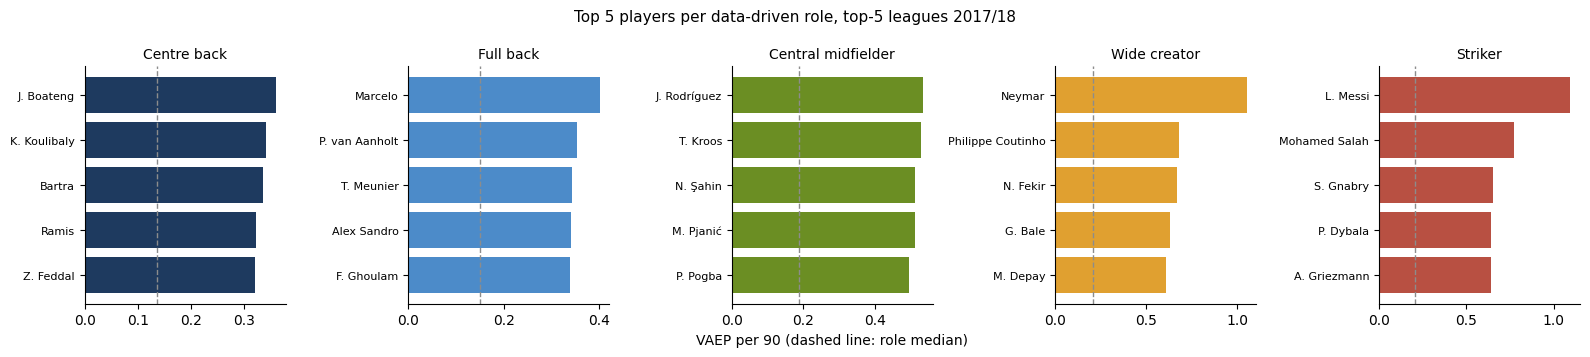


VAEP per 90 by role (median):
role
Centre back           0.136
Full back             0.151
Central midfielder    0.187
Wide creator          0.208
Striker               0.208
Name: vaep_p90, dtype: float64


In [10]:
ROLE_ORDER = ["Centre back", "Full back", "Central midfielder", "Wide creator", "Striker"]

out["pct_in_role"] = out.groupby("role")["vaep_p90"].rank(pct=True) * 100
out["off_share"] = out["off"] / (out["off"] + out["deff"].clip(lower=0))

cols = ["name", "team", "league", "official_role", "minutes", "vaep_p90", "pct_in_role"]
top = (out.sort_values("vaep_p90", ascending=False)
          .groupby("role", sort=False).head(10)
          .sort_values(["role", "vaep_p90"], ascending=[True, False]))
top[["role"] + cols].to_csv(WORK / "top10_per_role.csv", index=False)

for r in ROLE_ORDER:
    print(f"\n=== {r} ===")
    print(top[top["role"] == r][cols].round(3).to_string(index=False))

# Figure: top 5 per role
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharex=False)
for ax, r in zip(axes, ROLE_ORDER):
    g = top[top["role"] == r].head(5).iloc[::-1]
    ax.barh(g["name"], g["vaep_p90"], color=COLORS[r])
    ax.axvline(out.loc[out["role"] == r, "vaep_p90"].median(), color="#8C8C8C",
               linestyle="--", linewidth=1)
    ax.set_title(r, fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[2].set_xlabel("VAEP per 90 (dashed line: role median)")
plt.suptitle("Top 5 players per data-driven role, top-5 leagues 2017/18", fontsize=11)
plt.tight_layout()
plt.savefig(WORK / "fig_top5_per_role.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nVAEP per 90 by role (median):")
print(out.groupby("role")["vaep_p90"].median().reindex(ROLE_ORDER).round(3))